# Tarea 5: arquitectura e infraestructura en AWS
Diseño conceptual para operacionalizar la solución de las Tareas 3 y 4: corregir el pronóstico base y aplicar el gate de 45 días. No incluye código de infraestructura; interesa el razonamiento de diseño.

**Alcance honesto:** la solución se desarrolló y probó localmente en Docker. Esta arquitectura **no está desplegada ni probada en AWS**.

**Diagramas:** la fuente está en `docs/diagramas/` (Mermaid, `.mmd`), junto con los exportes `.svg` y `.png` que se muestran aquí.

**Principio de diseño:** el mismo código y la misma imagen de contenedor corren en desarrollo y en producción. Lo único que cambia son las variables de entorno (`LF_DATA_URI`, `LF_ARTIFACTS_URI`, `LF_MIN_HISTORY_DAYS`), de `/app/data/raw` a `s3://...`.

Los tres componentes que pide el enunciado son **batch / re-entrenamiento**, **servicio de inferencia** y **persistencia**. Se agrega **observabilidad**, porque un modelo de corrección sin monitoreo puede empeorar el pronóstico sin que nadie lo note.

## 1. Diagrama de la arquitectura


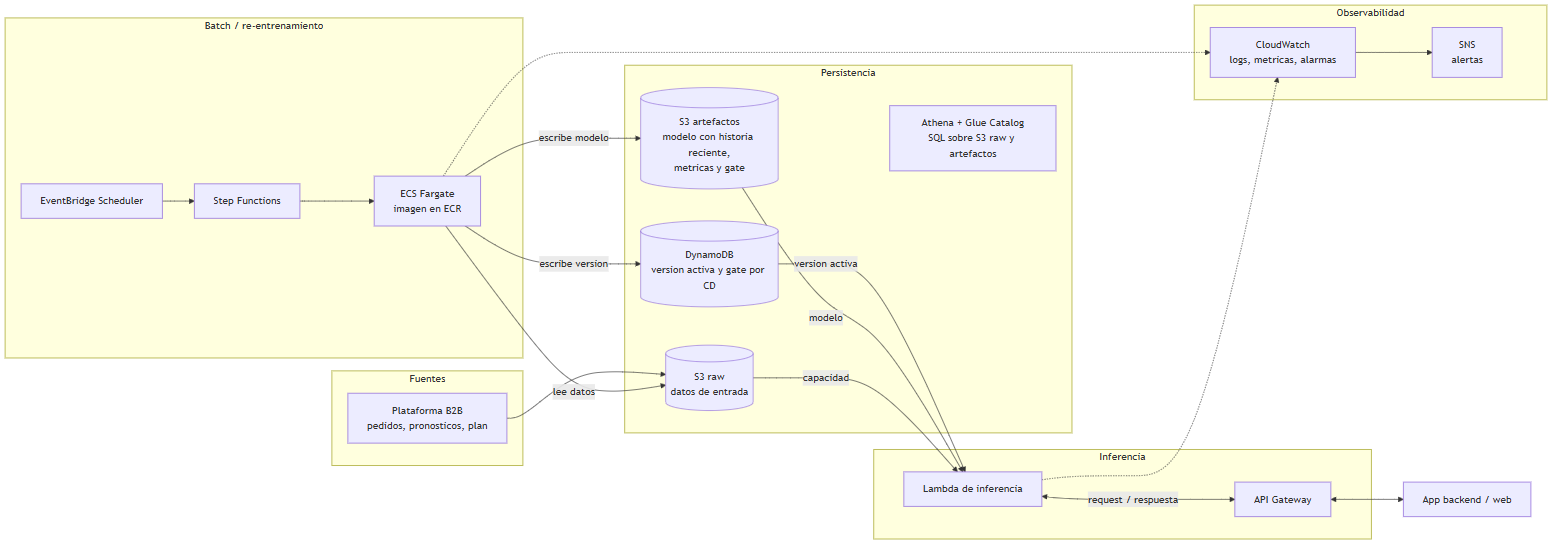

In [1]:
from IPython.display import Image

Image(filename="../docs/diagramas/01_arquitectura.png", width=1000)

## 2. Componentes y qué hace cada uno

| Bloque | Componente | Función |
|---|---|---|
| Batch | **EventBridge Scheduler** | Dispara el ciclo cada día, después de que llegan los reales y los pronósticos nuevos. |
| Batch | **Step Functions** | Orquesta los pasos con reintentos y ramas de error: calidad de datos, gate, entrenamiento, backtest, publicación. Deja trazabilidad de cada ejecución. |
| Batch | **ECS Fargate + ECR** | Corre la tarea pesada (`python -m logforecast.cli train`) en un contenedor sin servidor. Lee datos de S3, entrena, hace el backtest y escribe resultados. La imagen es la misma del Docker de desarrollo. |
| Inferencia | **API Gateway** | Expone el endpoint a la app backend / web. Autenticación, límites de tasa y validación del request. |
| Inferencia | **Lambda de inferencia** | Recibe el pronóstico base, carga el modelo vigente (ElasticNet con gate, que trae la historia reciente que necesitan las features) y devuelve el pronóstico corregido con la alerta de capacidad del día. Si el CD está en fallback o el modelo falla, devuelve el base. |
| Persistencia | **S3 raw** | Datos de entrada (pedidos, pronósticos, capacidad, plan), particionados por fecha. |
| Persistencia | **S3 artefactos** | Modelos versionados (cada artefacto incluye la historia reciente de reales para calcular las features), métricas del backtest, decisiones del gate. Histórico completo. |
| Persistencia | **DynamoDB** | Estado de lectura rápida por CD: versión de modelo activa y decisión del gate. |
| Persistencia | **Athena + Glue Catalog** | Consultas SQL sobre S3 para auditar errores, comparar versiones y revisar el WAPE histórico sin montar una base de datos. |
| Observabilidad | **CloudWatch + SNS** | Logs, métricas y alarmas (ver sección 6). SNS avisa por correo o chat. |

## 3. Flujos

### 3.1 Batch diario: entrenar y publicar


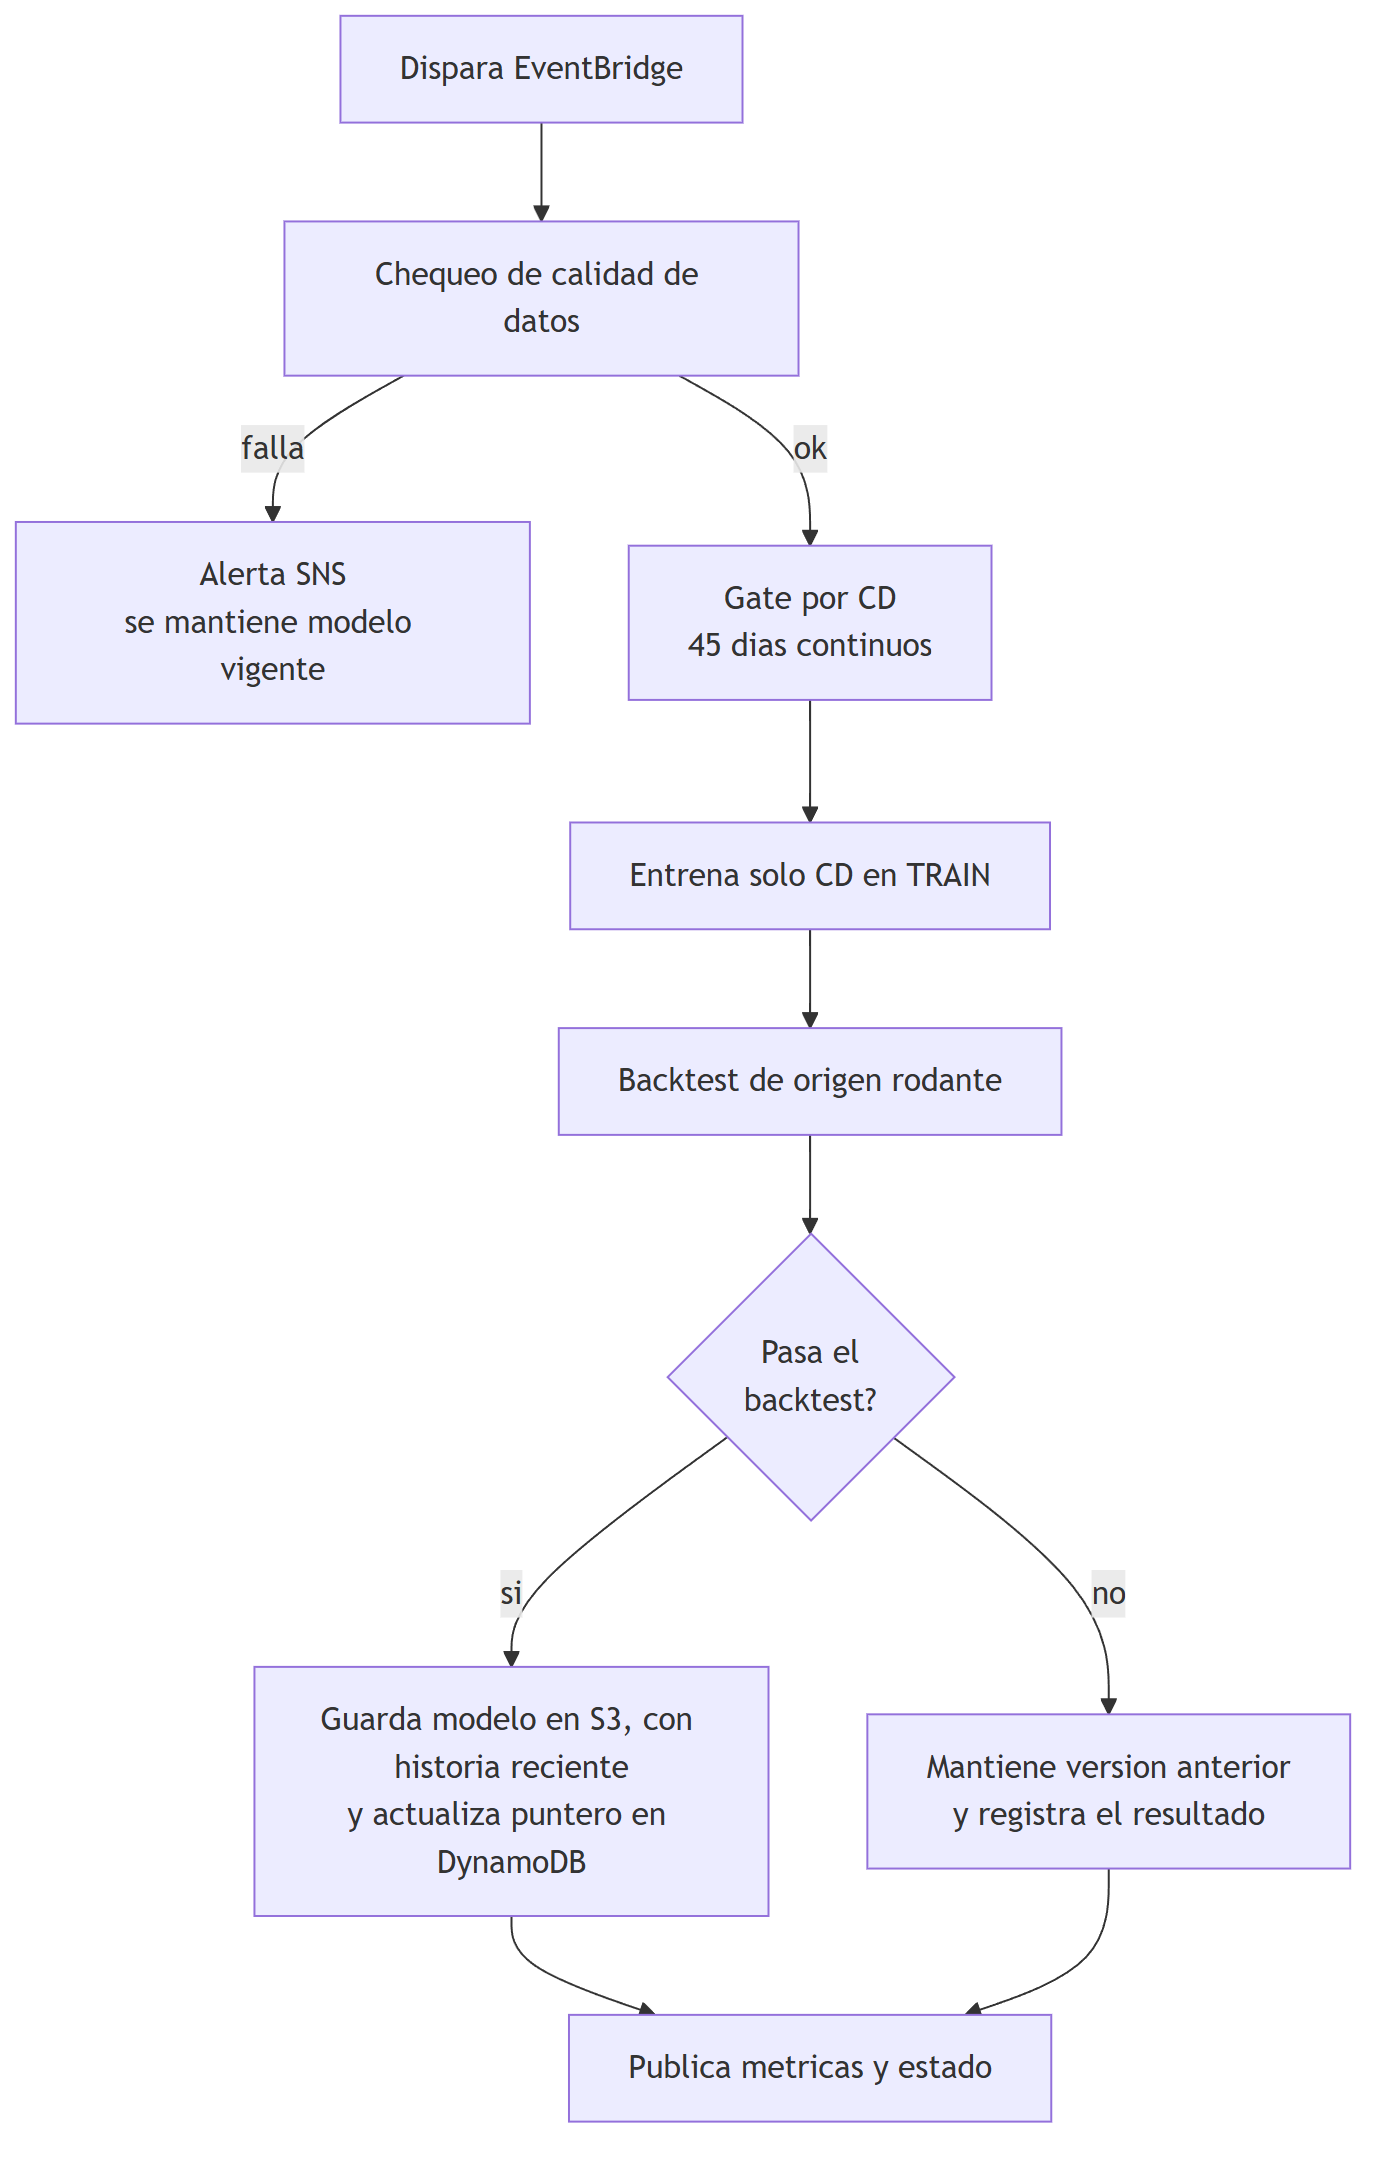

In [2]:
Image(filename="../docs/diagramas/02_batch_diario.png", width=480)

El batch corre **a diario** aunque los datos cambien poco: además de reentrenar, deja en el artefacto los reales del día anterior, que la inferencia necesita para las features (errores móviles, demanda reciente, real de la semana anterior, umbral de pico). Si el batch no corre, la Lambda sigue respondiendo con la historia anterior y registra una advertencia.

La nueva versión solo se activa si pasa el backtest: mejora el WAPE contra el pronóstico base y no empeora contra la versión vigente. Activar es mover un puntero en DynamoDB, y **revertir** es mover el puntero a la versión anterior, sin redesplegar nada.

### 3.2 Inferencia: pedir un pronóstico corregido


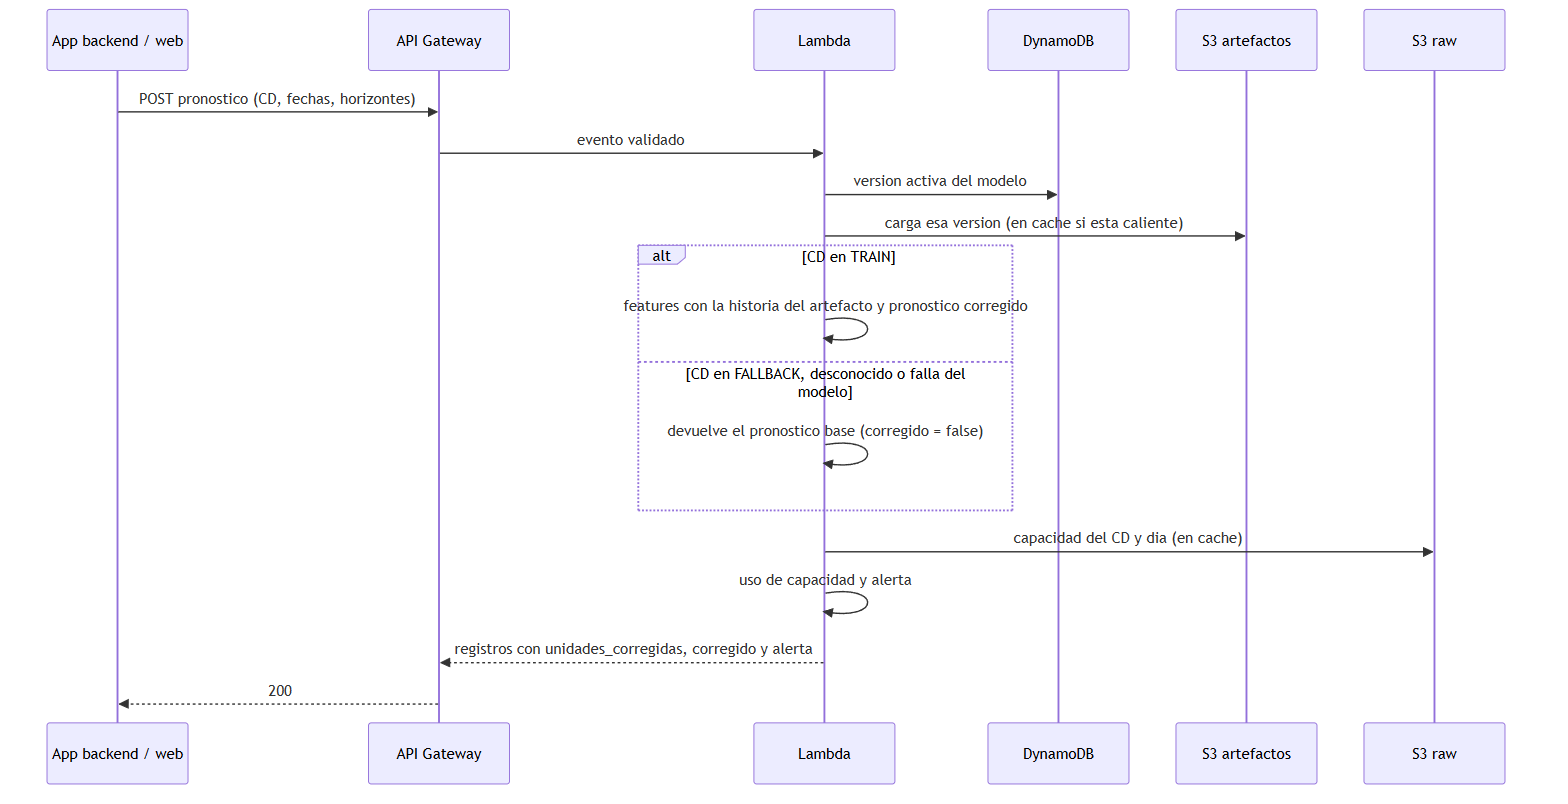

In [3]:
Image(filename="../docs/diagramas/03_inferencia.png", width=1000)

**Contrato (el que implementa `handlers/lambda_handler.py`):**

```json
// request: un registro por CD, emisión, despacho y horizonte (las 5 columnas son obligatorias)
{"records": [
  {"centro_distribucion": "CD_NORTE", "fecha_emision": "2026-03-02", "fecha_despacho": "2026-03-03",
   "horizonte": "D+1", "unidades_pronosticadas": 1200.0},
  {"centro_distribucion": "CD_NUEVO", "fecha_emision": "2026-03-02", "fecha_despacho": "2026-03-03",
   "horizonte": "D+1", "unidades_pronosticadas": 980.0}]}

// response 200: los mismos registros con la corrección y la alerta de capacidad
{"records": [
  {..., "unidades_corregidas": 1310.4, "corregido": true,
   "capacidad_maxima": 3600.0, "uso_capacidad": 0.364, "alerta_capacidad": "OK"},
  {..., "unidades_corregidas": 980.0, "corregido": false,
   "capacidad_maxima": null, "uso_capacidad": null, "alerta_capacidad": "SIN_CAPACIDAD"}]}

// response 400: falta una columna obligatoria
{"error": "payload invalido: faltan columnas: ['fecha_emision']"}
```
Con un request válido, el endpoint **siempre responde 200 con un número usable**. `corregido: false` indica que se devolvió el pronóstico base (CD en fallback o desconocido, o el modelo no se pudo cargar o falló).

**Capacidad y alerta.** Cada ítem trae la capacidad máxima del CD ese día (`capacidad_maxima`), el uso (`uso_capacidad` = corregido / capacidad) y `alerta_capacidad`: `OK`, `CERCA` (uso desde 90 %, configurable con `LF_CAPACITY_WARN_RATIO`), `EXCEDE` (uso sobre 100 %) o `SIN_CAPACIDAD` (no hay dato para ese CD y fecha; no es un error). La alerta **no modifica las unidades**: la app decide si recorta, reasigna o avisa. En el diagnóstico (notebook 07), más del 20 % de los pronósticos base excedía la capacidad, casi siempre sobreestimando; con el modelo corregido eso baja a ~2 %. Si la tabla de capacidad no se puede leer, el endpoint responde igual con `SIN_CAPACIDAD`.

### 3.3 Monitoreo y rollback

Cuando llegan los reales, un paso del batch calcula el WAPE y el sesgo del pronóstico corregido contra el base, por CD. Si el corregido es peor que el base durante varios días seguidos, salta una alarma y se apaga la corrección (el puntero pasa a "solo base") hasta revisar.

## 4. Persistencia: qué vive dónde

**S3 raw** (entrada, inmutable):
```
raw/pedidos/fecha=YYYY-MM-DD/...
raw/pronosticos/fecha_emision=YYYY-MM-DD/...
raw/capacidad/ ...   raw/plan_entrega/ ...
```

**S3 artefactos** (salida del batch, versionada por fecha de entrenamiento):
```
artefactos/modelos/version=YYYY-MM-DD/model.joblib
artefactos/metricas/version=YYYY-MM-DD/backtest.parquet
artefactos/gate/fecha=YYYY-MM-DD/gate_status.json
```

**DynamoDB** (clave de partición = centro de distribución):

| Campo | Contenido |
|---|---|
| `cd` | Clave: `CD_NORTE`, `CD_SUR`, ... |
| `gate_estado`, `dias_historia`, `razon` | Decisión del gate vigente |
| `version_modelo` | Puntero a la versión activa en S3 (o `SOLO_BASE`) |
| `actualizado_en` | Para detectar estado viejo |

**Historia para las features:** los reales y errores recientes que necesitan `err_7`, `err_14`, `pron_vs_rec7`, `pico_margen` y `lag7_rel` viajan dentro del artefacto del modelo (`model.joblib`), versionados con él; con 6 CD y 60 días son unas 1.400 filas. Así la inferencia calcula las features con la misma función que el backtest y no hay un segundo almacén que mantener sincronizado.

**Por qué dos almacenes:** S3 es barato y sirve para histórico, auditoría y Athena, pero la inferencia necesita una lectura rápida por clave; para eso va DynamoDB. Con 6 CD la tabla es minúscula.

## 5. Resiliencia y la regla de 45 días en producción
- **Gate integrado:** el batch evalúa el gate por CD; la decisión viaja en el artefacto del modelo (y se copia a DynamoDB para monitoreo). La inferencia la aplica. Un CD nuevo queda en fallback hasta juntar 45 días continuos y pasa a modelo solo, sin intervención.
- **Nunca un error por culpa del modelo:** si el modelo no se puede cargar o falla al predecir, la Lambda devuelve el pronóstico base con `corregido: false` y registra el error en CloudWatch (la carga se reintenta en el siguiente request). Un request inválido (falta una columna obligatoria) responde 400. La razón del gate queda en `gate_status.json`.
- **Publicación segura:** solo se activa una versión que pasa el backtest; si no, se mantiene la anterior. El rollback es un cambio de puntero.
- **Calidad de datos primero:** si el chequeo falla (huecos, duplicados, valores imposibles), no se entrena y se alerta. El sistema sigue sirviendo con el modelo vigente.
- **Idempotencia:** cada corrida se identifica por la fecha de emisión; reintentar no duplica artefactos ni cambia el resultado.
- **Umbral configurable:** el `LF_MIN_HISTORY_DAYS` es una variable de entorno, así que se puede ajustar sin tocar código (ver los trade-offs en la Tarea 4).

## 6. Observabilidad
| Qué se mide | Para qué | Alarma |
|---|---|---|
| WAPE y sesgo del corregido contra el base, por CD, en ventanas de 7 y 14 días | Detectar que la corrección dejó de ayudar (deriva) | Corregido peor que base varios días seguidos |
| % de filas en fallback y CD en fallback | Cobertura real del modelo | Un CD que debería estar en TRAIN aparece en fallback |
| Antigüedad del modelo activo | Detectar que el batch dejó de correr | Más de 2 días sin versión nueva |
| Errores y latencia de la Lambda | Salud del servicio | Tasa de errores o latencia sobre el umbral |
| Duración y fallos de la tarea ECS | Salud del batch | Tarea fallida o fuera de tiempo |

Las alarmas de CloudWatch publican en SNS (correo o chat del equipo).

## 7. Seguridad
- **IAM de mínimo privilegio, un rol por componente:** la tarea ECS lee `raw` y escribe `artefactos` y la tabla; la Lambda solo lee `artefactos`, la tabla y `raw/capacidad`; nadie tiene permisos de más.
- **S3:** acceso público bloqueado, cifrado en reposo y versionado activado.
- **API Gateway:** autenticación (IAM o Cognito), límites de tasa y validación del esquema del request.
- **ECR:** escaneo de vulnerabilidades en cada imagen y versión fija de las dependencias.
- **Logs:** sin datos sensibles de clientes; el plan de entrega usa identificadores genéricos.

## 8. Decisiones y alternativas
| Decisión | Por qué | Alternativa y cuándo cambiaría |
|---|---|---|
| **Entrenar en ECS Fargate** | Misma imagen que en desarrollo, sin el límite de 15 minutos ni de memoria de Lambda, con margen para más CD, más historia o un modelo más pesado. | Hoy el entrenamiento dura segundos y una Lambda alcanzaría. Se elige Fargate por margen de crecimiento, no por necesidad actual. |
| **Inferencia en Lambda + API Gateway** | Modelo liviano (un ElasticNet son pocos coeficientes, más la historia reciente de 6 CD), tráfico irregular y pago por uso. | Con tráfico alto y sostenido o latencia estricta: servicio en ECS detrás de un balanceador, o concurrencia aprovisionada en Lambda para evitar los arranques en frío. |
| **Step Functions** en vez de un cron | Reintentos, ramas de error y trazabilidad por paso. | Para un solo paso, EventBridge directo a ECS bastaría. |
| **DynamoDB + S3** | Estado de lectura rápida por clave más histórico barato y consultable. | Todo en S3 es más simple, pero cada inferencia leería archivos. |
| **Sin SageMaker** | Un ElasticNet con 6 CD no justifica su costo y complejidad. | Con muchos modelos, registro formal de versiones o entrenamiento distribuido, sí. |
| **Historia para las features dentro del artefacto** | Una sola fuente, versionada con el modelo; la inferencia usa la misma función de features que el backtest, así que no hay desfase entre entrenamiento e inferencia. | Con muchos CD o historia larga el artefacto crece y la Lambda tarda más en cargarlo: guardar solo la ventana reciente por CD en DynamoDB o en un feature store. |
| **Inferencia bajo demanda** | Las features usan el último real conocido y el pronóstico recibido. | Un batch nocturno que precalcule los pronósticos corregidos y la API solo los lea es más simple y barato, pero menos flexible. |

## 9. Cómo se corresponde con el repositorio
| Pieza de la arquitectura | Código del repo | Estado |
|---|---|---|
| Tarea de entrenamiento en ECS | `python -m logforecast.cli train` (`cli.py`, `pipeline.train()`) | Implementado: entrena el ElasticNet con gate y escribe `model.joblib` y `gate_status.json`. Sin backtest de publicación ni versionado por fecha. |
| Lambda de inferencia | `handlers/lambda_handler.py` (`pipeline.predict()`) | Implementado: contrato, fallback al base y alerta de capacidad. Lee el modelo directo de `LF_ARTIFACTS_URI`, sin puntero en DynamoDB. |
| Modelo de corrección (ElasticNet) | `ElasticNetCorrector` en `model.py` (mismas features que la CV, `cv.ELEGIDO`) | Implementado; un test verifica que predice igual que el backtest. |
| Gate y fallback | `gate.py`, `GatedCorrector` en `model.py` | Implementado. |
| Lectura local o S3 con el mismo código | `io.py` y `config.py` (`s3://...` por variable de entorno) | Implementado (probado solo con rutas locales). |
| Chequeo de calidad | `quality.py` (`python -m logforecast.cli quality`) | Implementado, pero no se encadena antes del entrenamiento. |
| Imagen de contenedor | `Dockerfile` | Implementado. |
| Step Functions, DynamoDB, publicación condicionada, monitoreo y rollback, Athena | — | Solo diseño. |

## 10. Fuera de alcance (a declarar)
- **No hay despliegue ni pruebas en AWS.** La arquitectura es un diseño; el código solo se ejecutó en Docker.
- **Sin infraestructura como código**, como indica el enunciado.
- **Sin diseño de CI/CD** (construir la imagen y subirla a ECR), de red (VPC, endpoints privados) ni de costos.
- **Sin pruebas de carga** ni definición de SLA de latencia.
- **Sin registro formal de modelos:** el versionado es por carpeta en S3 y un puntero en DynamoDB.
- **Publicación condicionada no implementada:** `cli train` entrena y sobrescribe el artefacto; el backtest previo a activar una versión y el puntero en DynamoDB son parte del diseño.